Tune hyperparameters for XGBoost using a manually implemented random search algorithm instead of RandomizedSearchCV, ensuring an efficient yet comprehensive exploration of parameter space.

In [1]:
import pandas as pd
import numpy as np
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

df = pd.read_csv("heart_disease_train.csv")

features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
target = "target"

df = df[features + [target]].dropna()

X = df[features]
y = df[target].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 63
Testing records: 16


In [2]:
parameter_space = {
    "n_estimators": [50, 100, 150],
    "max_depth": [2, 3, 4, 5],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.7, 0.8, 1.0]
}

np.random.seed(42)

search_results = []

In [3]:
import random

random.seed(42)

all_combinations = []

for n in parameter_space["n_estimators"]:
    for depth in parameter_space["max_depth"]:
        for rate in parameter_space["learning_rate"]:
            for sub in parameter_space["subsample"]:
                for col in parameter_space["colsample_bytree"]:
                    all_combinations.append({
                        "n_estimators": n,
                        "max_depth": depth,
                        "learning_rate": rate,
                        "subsample": sub,
                        "colsample_bytree": col
                    })

selected_parameters = random.sample(
    all_combinations, min(10, len(all_combinations))
)

best_accuracy = 0
best_parameters = None

for i, params in enumerate(selected_parameters, start=1):
    model = XGBClassifier(
        **params,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions) * 100

    search_results.append({
        **params,
        "Accuracy": accuracy
    })

    print("Trial:", i, "| Accuracy:", round(accuracy, 2), "%")

    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_parameters = params.copy()

print("\nBest Parameters:")
print(best_parameters)
print("Best Accuracy:", round(best_accuracy, 2), "%")

Trial: 1 | Accuracy: 75.0 %
Trial: 2 | Accuracy: 81.25 %
Trial: 3 | Accuracy: 81.25 %
Trial: 4 | Accuracy: 81.25 %
Trial: 5 | Accuracy: 81.25 %
Trial: 6 | Accuracy: 81.25 %
Trial: 7 | Accuracy: 75.0 %
Trial: 8 | Accuracy: 81.25 %
Trial: 9 | Accuracy: 81.25 %
Trial: 10 | Accuracy: 81.25 %

Best Parameters:
{'n_estimators': 50, 'max_depth': 3, 'learning_rate': 0.1, 'subsample': 0.8, 'colsample_bytree': 0.7}
Best Accuracy: 81.25 %


In [4]:
results_df = pd.DataFrame(search_results)
results_df = results_df.sort_values(
    by="Accuracy", ascending=False
).reset_index(drop=True)

print(results_df.round(2).to_string(index=False))

 n_estimators  max_depth  learning_rate  subsample  colsample_bytree  Accuracy
           50          3           0.10        0.8               0.7     81.25
           50          2           0.05        0.8               0.7     81.25
           50          3           0.20        1.0               1.0     81.25
          150          4           0.10        0.7               0.8     81.25
           50          5           0.20        0.8               1.0     81.25
           50          5           0.05        1.0               1.0     81.25
           50          3           0.05        1.0               0.8     81.25
          150          4           0.05        1.0               1.0     81.25
          150          3           0.01        0.8               0.7     75.00
           50          5           0.01        1.0               0.7     75.00


In [5]:
best_model = XGBClassifier(
    **best_parameters,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

best_model.fit(X_train, y_train)

final_predictions = best_model.predict(X_test)

final_accuracy = accuracy_score(y_test, final_predictions) * 100

print("Best XGBoost Model Results")
print("Best Parameters:", best_parameters)
print("Final Accuracy:", round(final_accuracy, 2), "%")

Best XGBoost Model Results
Best Parameters: {'n_estimators': 50, 'max_depth': 3, 'learning_rate': 0.1, 'subsample': 0.8, 'colsample_bytree': 0.7}
Final Accuracy: 81.25 %


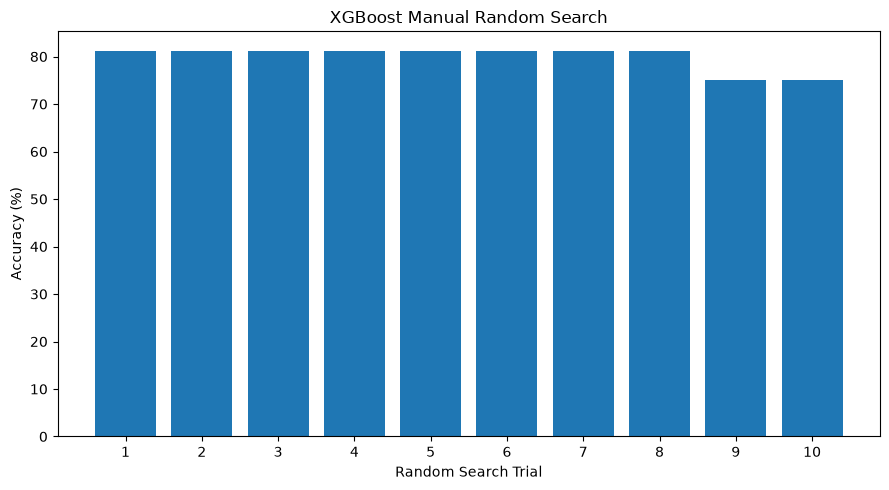

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    range(1, len(results_df) + 1),
    results_df["Accuracy"]
)

plt.xlabel("Random Search Trial")
plt.ylabel("Accuracy (%)")
plt.title("XGBoost Manual Random Search")
plt.xticks(range(1, len(results_df) + 1))
plt.tight_layout()
plt.show()